# 02 · Exploratory analysis: where do the three sources disagree?

Goal for Day 2: before writing the matching engine, understand the *shape* of the differences — how many, how large, when, and on which payment methods — so the matching rules are designed around real patterns rather than guesses.

Sections
1. First-pass match of ERP receipts to gateway payments on the normalised order id
2. The month-end cut-off (IST ledger vs UTC gateway report)
3. Amount differences
4. Gateway fees vs the contracted rates
5. Refunds and chargebacks
6. Payouts vs bank
7. Are breaks concentrated by payment method or channel? (chi-square)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

pd.set_option("display.width", 160)
ROOT = Path.cwd().parent
CLEAN, IMG = ROOT / "data" / "clean", ROOT / "images"
IMG.mkdir(exist_ok=True)

led = pd.read_parquet(CLEAN / "ledger.parquet")
gw = pd.read_parquet(CLEAN / "gateway_txns.parquet")
po = pd.read_parquet(CLEAN / "payouts.parquet")
bank = pd.read_parquet(CLEAN / "bank.parquet")

CONTRACT = {"UPI": 0.0030, "Card": 0.0190, "NetBanking": 0.0150, "Wallet": 0.0200}
INK, MUTED, ACCENT, WARN, OK = "#1f2937", "#9ca3af", "#2563eb", "#dc2626", "#16a34a"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
lakh = lambda x: f"₹{x/1e5:,.2f} L"
print(f"ledger {len(led):,} | gateway {len(gw):,} | payouts {len(po)} | bank {len(bank)}")

ledger 24,149 | gateway 24,250 | payouts 32 | bank 111


## 1 · First-pass match on order id

ERP receipts vs gateway *payment* rows (captured or failed), full outer join on the normalised `order_id`. No tolerance or timing logic yet — this is the raw picture the engine has to improve on.

In [2]:
rec = led[led.entry_type == "receipt"]
pay = gw[gw.type == "payment"]
m = rec.merge(pay[["order_id", "txn_id", "status", "amount_inr", "ts_ist", "method", "in_period_ist"]],
              on="order_id", how="outer", suffixes=("_erp", "_gw"), indicator=True)

diff = (m.amount_inr_erp - m.amount_inr_gw).abs()
m["bucket"] = np.select(
    [m._merge.eq("left_only"),
     m._merge.eq("right_only") & m.status.eq("captured"),
     m._merge.eq("right_only"),
     m.status.eq("failed"),
     diff.eq(0), diff.le(1)],
    ["ERP only: no gateway record", "Gateway only: not booked", "Gateway only: failed attempt",
     "ERP booked, gateway FAILED", "Exact match", "Match within ±₹1"],
    "Amount differs > ₹1")
m["value_inr"] = m.amount_inr_erp.fillna(m.amount_inr_gw)
summary = (m.groupby("bucket").agg(rows=("order_id", "size"), value_inr=("value_inr", "sum"))
             .sort_values("rows", ascending=False))
summary["share_rows"] = (summary.rows / summary.rows.sum()).map("{:.2%}".format)
summary["value"] = summary.value_inr.map(lakh)
summary[["rows", "share_rows", "value"]]

,rows,share_rows,value
bucket,,,
Exact match,23435,97.74%,₹218.28 L
ERP only: no gateway record,156,0.65%,₹1.66 L
Gateway only: not booked,121,0.50%,₹1.09 L
Amount differs > ₹1,114,0.48%,₹0.97 L
"ERP booked, gateway FAILED",77,0.32%,₹0.59 L
Match within ±₹1,73,0.30%,₹0.65 L


In [3]:
exact = summary.loc["Exact match", "rows"]; total = summary.rows.sum()
breaks = summary.drop(["Exact match", "Match within ±₹1"])
print(f"Exact matches: {exact:,} of {total:,} keys ({exact/total:.1%})")
print(f"Keys needing a decision: {breaks.rows.sum():,} worth {lakh(breaks.value_inr.sum())}")

Exact matches: 23,435 of 23,976 keys (97.7%)
Keys needing a decision: 468 worth ₹4.30 L


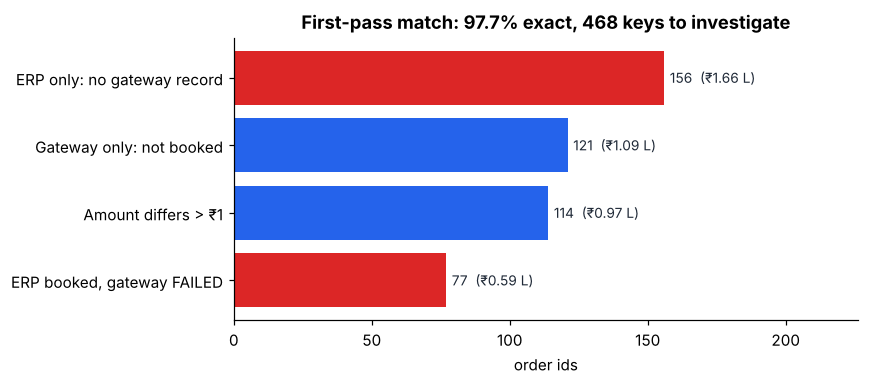

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
b = breaks.sort_values("rows")
ax.barh(b.index, b.rows, color=[WARN if "FAILED" in i or "no gateway" in i else ACCENT for i in b.index])
for y, (r, v) in enumerate(zip(b.rows, b.value_inr)):
    ax.text(r + 2, y, f"{r}  ({lakh(v)})", va="center", fontsize=9, color=INK)
ax.set_xlabel("order ids")
ax.set_title(f"First-pass match: {exact/total:.1%} exact, {breaks.rows.sum()} keys to investigate")
ax.set_xlim(0, b.rows.max() * 1.45)
plt.tight_layout(); plt.savefig(IMG / "01_first_pass_match.png", dpi=150, bbox_inches="tight"); plt.show()

## 2 · The month-end cut-off

The ERP books in IST. The gateway report was exported for **1–31 Oct UTC**, i.e. 05:30 IST on 1 Oct to 05:30 IST on 1 Nov. If that is right, unmatched ERP rows should pile up on 1 Oct before 05:30 and unmatched gateway rows on 1 Nov before 05:30.

In [5]:
erp_only = m[m.bucket == "ERP only: no gateway record"]
gw_only = m[m.bucket == "Gateway only: not booked"]
early_oct1 = erp_only.posting_ts_ist.lt("2026-10-01 05:30").sum()
nov1 = gw_only.ts_ist.ge("2026-11-01").sum()
print(f"ERP-only rows posted 1 Oct 00:00–05:30 IST : {early_oct1} of {len(erp_only)}  ({lakh(erp_only.loc[erp_only.posting_ts_ist.lt('2026-10-01 05:30'), 'value_inr'].sum())})")
print(f"Gateway-only rows dated 1 Nov IST          : {nov1} of {len(gw_only)}  ({lakh(gw_only.loc[gw_only.ts_ist.ge('2026-11-01'), 'value_inr'].sum())})")
print(f"=> {early_oct1 + nov1} of {len(erp_only) + len(gw_only)} 'missing' rows are a report-extraction artefact, not real breaks")

ERP-only rows posted 1 Oct 00:00–05:30 IST : 62 of 156  (₹0.63 L)
Gateway-only rows dated 1 Nov IST          : 50 of 121  (₹0.47 L)
=> 112 of 277 'missing' rows are a report-extraction artefact, not real breaks


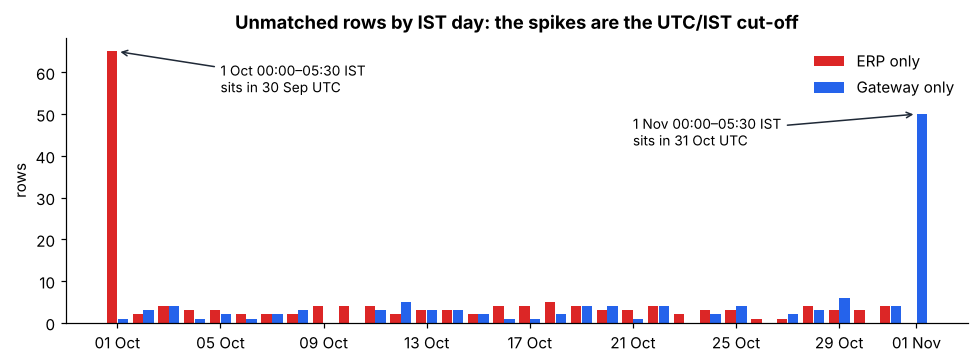

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.4))
d1 = erp_only.posting_ts_ist.dt.floor("D").value_counts().sort_index()
d2 = gw_only.ts_ist.dt.floor("D").value_counts().sort_index()
days = pd.date_range("2026-10-01", "2026-11-01")
ax.bar(days - pd.Timedelta(hours=5), d1.reindex(days, fill_value=0), width=0.4, color=WARN, label="ERP only")
ax.bar(days + pd.Timedelta(hours=5), d2.reindex(days, fill_value=0), width=0.4, color=ACCENT, label="Gateway only")
ax.annotate("1 Oct 00:00–05:30 IST\nsits in 30 Sep UTC", xy=(days[0], d1.max()), xytext=(days[4], d1.max() * 0.85),
            arrowprops=dict(arrowstyle="->", color=INK), fontsize=9)
ax.annotate("1 Nov 00:00–05:30 IST\nsits in 31 Oct UTC", xy=(days[-1], d2.max()), xytext=(days[-12], d2.max() * 0.85),
            arrowprops=dict(arrowstyle="->", color=INK), fontsize=9)
ax.set_title("Unmatched rows by IST day: the spikes are the UTC/IST cut-off")
ax.set_ylabel("rows"); ax.legend(frameon=False)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
plt.tight_layout(); plt.savefig(IMG / "02_cutoff_spikes.png", dpi=150, bbox_inches="tight"); plt.show()

**Implication for the engine:** pull the gateway report by IST date (or widen the window by ±1 day and filter after converting to IST), and classify rows within 05:30 of a month boundary as *timing* rather than *break*.

## 3 · Amount differences

Only keys present on both sides with status captured. Are the differences random noise or a pattern?

In [7]:
both = m[m._merge.eq("both") & m.status.eq("captured")].copy()
both["diff_inr"] = both.amount_inr_gw - both.amount_inr_erp
both["diff_pct"] = both.diff_inr / both.amount_inr_erp
nz = both[both.diff_inr != 0]
print(f"non-zero differences: {len(nz)}")
print(f"  |diff| <= ₹1        : {(nz.diff_inr.abs() <= 1).sum()}  (net {nz.loc[nz.diff_inr.abs() <= 1, 'diff_inr'].sum():+.0f} ₹)")
big = nz[nz.diff_inr.abs() > 1]
print(f"  |diff| >  ₹1        : {len(big)}  — gateway LOWER than ERP in {(big.diff_inr < 0).sum()} of {len(big)}")
print(f"  gap as % of ERP amount: min {big.diff_pct.min():.1%}, median {big.diff_pct.median():.1%}, max {big.diff_pct.max():.1%}")
print(f"  total under-collection: {lakh(-big.diff_inr.sum())}")

non-zero differences: 187
  |diff| <= ₹1        : 73  (net -1 ₹)
  |diff| >  ₹1        : 114  — gateway LOWER than ERP in 114 of 114
  gap as % of ERP amount: min -19.9%, median -12.3%, max -5.2%
  total under-collection: ₹0.12 L


Every difference above ₹1 goes the same way (gateway collected 5–20% *less* than the ERP booked). That pattern points to a discount applied at checkout after the ERP order was created — a process issue to raise with the e-commerce team, not random keying errors. The ±₹1 differences net to almost zero and should be auto-cleared by a tolerance rule.

## 4 · Gateway fees vs the contract

In [8]:
cap = gw[(gw.type == "payment") & gw.status.eq("captured") & gw.in_period_ist].copy()
cap["rate"] = cap.fee_inr / cap.amount_inr
cap["contract"] = cap.method.map(CONTRACT)
cap["expected_fee"] = (cap.amount_inr * cap.contract).round(2)
cap["excess_fee"] = cap.fee_inr - cap.expected_fee
cap["excess_incl_gst"] = cap.excess_fee * 1.18
fees = cap.groupby("method").agg(txns=("txn_id", "size"), gross=("amount_inr", "sum"), fee=("fee_inr", "sum"),
                                 contract=("contract", "first"), excess_incl_gst=("excess_incl_gst", "sum"),
                                 txns_over=("excess_fee", lambda s: (s > 0.02).sum()))
fees["effective_rate"] = fees.fee / fees.gross
out = fees[["txns", "contract", "effective_rate", "txns_over", "excess_incl_gst"]].copy()
out["contract"] = out.contract.map("{:.2%}".format); out["effective_rate"] = out.effective_rate.map("{:.3%}".format)
out["excess_incl_gst"] = out.excess_incl_gst.map("₹{:,.0f}".format)
out

,txns,contract,effective_rate,txns_over,excess_incl_gst
method,,,,,
Card,5920,1.90%,1.908%,87,₹509
NetBanking,2350,1.50%,1.500%,0,₹1
UPI,13014,0.30%,0.300%,0,₹-1
Wallet,2409,2.00%,2.135%,1308,"₹3,445"


In [9]:
w = cap[cap.method == "Wallet"].copy()
w["day"] = w.ts_ist.dt.floor("D")
daily = w.groupby("day").apply(lambda g: g.fee_inr.sum() / g.amount_inr.sum(), include_groups=False)
before, after = daily[daily.index < "2026-10-15"], daily[daily.index >= "2026-10-15"]
print(f"Wallet effective rate  before 15 Oct: {before.mean():.3%}  | from 15 Oct: {after.mean():.3%}")
card = cap[cap.method == "Card"]
print(f"Card txns charged above 1.90% (> 2 paise excess): {(card.excess_fee > 0.02).sum()} of {len(card)} "
      f"({(card.excess_fee > 0.02).mean():.2%}); their rate: {card.loc[card.excess_fee > 0.02, 'rate'].median():.2%}")
total_excess = cap.excess_incl_gst.sum()
print(f"Total fee charged above contract (incl. 18% GST), October: ₹{total_excess:,.0f}")

Wallet effective rate  before 15 Oct: 2.000%  | from 15 Oct: 2.250%
Card txns charged above 1.90% (> 2 paise excess): 87 of 5920 (1.47%); their rate: 2.40%
Total fee charged above contract (incl. 18% GST), October: ₹3,955


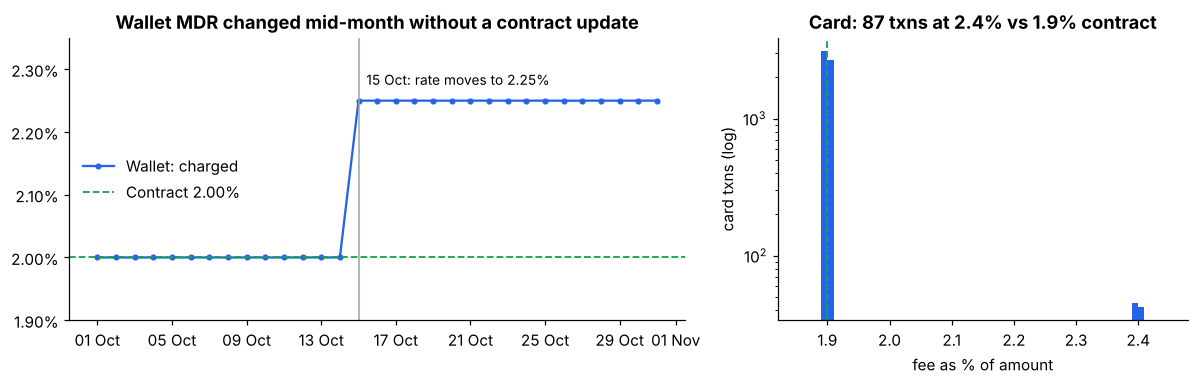

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.plot(daily.index, daily.values * 100, marker="o", ms=3, color=ACCENT, label="Wallet: charged")
ax.axhline(2.0, color=OK, ls="--", lw=1.2, label="Contract 2.00%")
ax.axvline(pd.Timestamp("2026-10-15"), color=MUTED, lw=1)
ax.text(pd.Timestamp("2026-10-15"), 2.27, "  15 Oct: rate moves to 2.25%", fontsize=9, va="bottom")
ax.set_ylim(1.9, 2.35); ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.2f%%"))
ax.set_title("Wallet MDR changed mid-month without a contract update"); ax.legend(frameon=False, loc="center left")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
ax = axes[1]
ax.hist(card.rate * 100, bins=np.arange(1.85, 2.46, 0.01), color=ACCENT)
ax.axvline(1.9, color=OK, ls="--", lw=1.2)
ax.set_yscale("log"); ax.set_xlabel("fee as % of amount"); ax.set_ylabel("card txns (log)")
ax.set_title(f"Card: {(card.excess_fee > 0.02).sum()} txns at 2.4% vs 1.9% contract")
plt.tight_layout(); plt.savefig(IMG / "03_fee_vs_contract.png", dpi=150, bbox_inches="tight"); plt.show()

## 5 · Refunds and chargebacks missing from the books

In [11]:
rf = gw[(gw.type == "refund") & gw.in_period_ist]
cn = led[led.entry_type == "credit_note"]
rfm = rf.merge(cn[["order_id", "amount_inr"]], on="order_id", how="left", suffixes=("", "_cn"))
unbooked = rfm[rfm.amount_inr_cn.isna()]
print(f"Gateway refunds in October (IST): {len(rf)} worth {lakh(rf.amount_inr.sum())}")
print(f"With an ERP credit note: {rfm.amount_inr_cn.notna().sum()}  |  without: {len(unbooked)} worth {lakh(unbooked.amount_inr.sum())} ({len(unbooked)/len(rf):.0%})")
cb = po[po.chargeback_inr > 0]
print(f"Chargebacks deducted from payouts: {lakh(cb.chargeback_inr.sum())} across {len(cb)} settlements — none have an ERP entry")

Gateway refunds in October (IST): 427 worth ₹3.29 L
With an ERP credit note: 294  |  without: 133 worth ₹1.05 L (31%)
Chargebacks deducted from payouts: ₹0.25 L across 11 settlements — none have an ERP entry


## 6 · Payouts vs bank

In [12]:
bk = bank[bank.category == "gateway_settlement"][["value_date", "utr", "credit"]]
pb = po.merge(bk, on="utr", how="left")
# expected credit date = contractual T+1 business day (no Sunday credits)
nbd = pb.batch_date + pd.Timedelta(days=1)
pb["expected_date"] = nbd + pd.to_timedelta((nbd.dt.weekday == 6).astype(int), unit="D")
pb["status"] = np.select([pb.credit.isna() & pb.expected_date.gt("2026-10-31"),
                          pb.credit.isna(),
                          (pb.credit - pb.net_inr).abs() > 0.01],
                         ["in transit (due after 31 Oct)", "MISSING (was due in October)", "amount differs"], "matched")
print(pb.status.value_counts().to_string())
print()
print(f"Settlement lag (batch day -> settlement): " + ", ".join(f"T+{k}: {v}" for k, v in po.lag_days.value_counts().sort_index().items()))
pb[pb.status != "matched"][["settlement_id", "batch_date", "expected_date", "settlement_date", "net_inr", "status"]]

status
matched                          30
MISSING (was due in October)      1
in transit (due after 31 Oct)     1

Settlement lag (batch day -> settlement): T+1: 26, T+2: 5, T+15: 1


,settlement_id,batch_date,expected_date,settlement_date,net_inr,status
19,setl_20261019,2026-10-19,2026-10-20,2026-11-03,641741.68,MISSING (was due in October)
31,setl_20261031,2026-10-31,2026-11-02,2026-11-02,664381.60,in transit (due after 31 Oct)


In [13]:
held = po[po.lag_days > 3]
print("Batches settled more than 3 days late:")
print(held[["settlement_id", "batch_date", "settlement_date", "lag_days", "net_inr"]].to_string(index=False))

Batches settled more than 3 days late:
settlement_id batch_date settlement_date  lag_days   net_inr
setl_20261019 2026-10-19      2026-11-03        15 641741.68


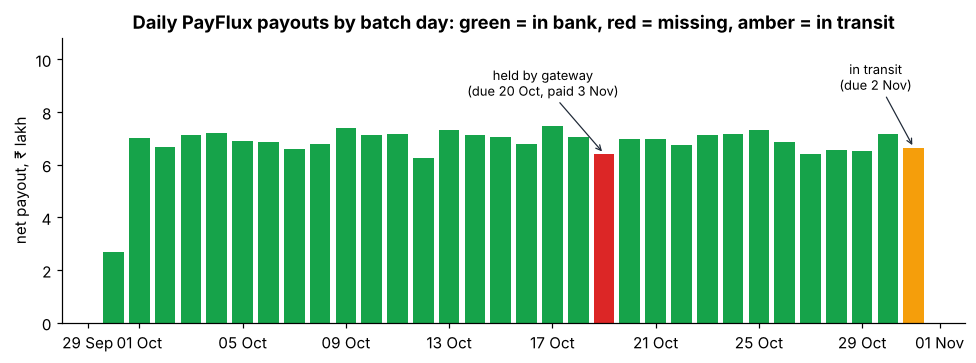

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.4))
s = pb.set_index("batch_date").sort_index()
ax.bar(s.index, s.net_inr / 1e5, color=[OK if x == "matched" else (WARN if x.startswith("MISSING") else "#f59e0b") for x in s.status], width=0.8)
for d, r in s[s.status != "matched"].iterrows():
    lbl = "held by gateway\n(due 20 Oct, paid 3 Nov)" if r.lag_days > 3 else "in transit\n(due 2 Nov)"
    ax.annotate(lbl, xy=(d, r.net_inr / 1e5), xytext=(-40 if r.lag_days > 3 else -25, 38), textcoords="offset points", ha="center", fontsize=8.5,
                bbox=dict(fc="white", ec="none", pad=1), arrowprops=dict(arrowstyle="->", color=INK, lw=0.8))
ax.set_ylabel("net payout, ₹ lakh"); ax.set_ylim(0, s.net_inr.max() / 1e5 * 1.45)
ax.set_title("Daily PayFlux payouts by batch day: green = in bank, red = missing, amber = in transit")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
plt.tight_layout(); plt.savefig(IMG / "04_payouts_vs_bank.png", dpi=150, bbox_inches="tight"); plt.show()

## 7 · Are breaks concentrated by payment method or channel?

If one integration (say, wallet) produced most of the breaks, the fix would be technical. Test: among ERP receipts (excluding the 1 Oct cut-off window), is the break rate independent of payment method / channel? Chi-square test of independence, α = 0.05.

In [15]:
t = m[m._merge.isin(["both", "left_only"]) & m.posting_ts_ist.ge("2026-10-01 05:30")].copy()
t["is_break"] = t.bucket.isin(["ERP only: no gateway record", "ERP booked, gateway FAILED", "Amount differs > ₹1"])
t = t[t.payment_mode != "Unknown"]
for col in ["payment_mode", "channel"]:
    ct = pd.crosstab(t[col], t.is_break)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    rate = (ct[True] / ct.sum(axis=1)).map("{:.2%}".format)
    print(f"{col}: chi2={chi2:.2f}, dof={dof}, p={p:.3f}   break rate -> {rate.to_dict()}")

payment_mode: chi2=4.65, dof=3, p=0.200   break rate -> {'Card': '1.24%', 'NetBanking': '1.28%', 'UPI': '1.26%', 'Wallet': '0.75%'}
channel: chi2=2.30, dof=2, p=0.317   break rate -> {'App': '1.28%', 'Instagram': '0.90%', 'Website': '1.19%'}


Neither test rejects independence at 5%: breaks are spread evenly across payment methods and channels. That points to **process** causes (manual bookings, checkout discounts, refunds not posted) rather than one faulty integration — useful for deciding who owns the fix.

## Summary of first findings

The numbers are printed in the cells above; the README repeats them.

1. A plain order-id join matches most keys exactly, but leaves a few hundred to investigate.
2. A large part of the "missing" rows is a **report cut-off artefact** (UTC export vs IST books), not real breaks.
3. All amount differences above ₹1 are under-collections of 5–20%: a checkout-discount process gap.
4. The gateway is charging **above contract** on Wallet (since 15 Oct) and on a slice of Card payments.
5. Refunds without credit notes and chargebacks are being netted out of payouts but are not in the ERP.
6. Two settlements are not in the October bank statement: one in transit (timing), one held by the gateway (needs follow-up).

**Next (Day 3):** turn these into SQL matching rules in DuckDB — exact, normalised, tolerance, timing window and many-to-one (payout ↔ transactions) — and produce the exception register.